In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from Krauklis_model import KrauklisParameters,KrauklisModel
from wavenumber_to_group import wavenumber_to_group
from scholte_wave import scholte_wave

In [ ]:
# ============================================================
# 1. Physical parameters
# ============================================================
# fluid
rho_f=1000.0
eta=1.0e-3
Kf=2.4e9
# fracture
w0=1.0e-3
L=10.0
# elastic rock
rho_s=2650.0
cp_s=5200.0
cs_s=3000.0

p = KrauklisParameters(
    # Fluid
    rho_f,
    eta,
    Kf,
    # Fracture
    w0,
    L,
    # Elastic rock
    rho_s,
    cp_s,  # velocity
    cs_s
)

In [8]:
# ============================================================
# 2. Frequency sweep
# ============================================================
# krauklis wave
model = KrauklisModel(p)
frequencies = np.logspace(-2, 7, 10000)
# Dynamic
result_dynamic = model.solve_spectrum(frequencies,dynamic=True)
# Quasistatic
result_static = model.solve_spectrum(frequencies,dynamic=False)

# Scholte_wave
cf=np.sqrt(Kf/rho_f)
v_scholte,k_scholte = scholte_wave(frequencies,rho_f,rho_s,cf,cp_s,cs_s)
print(v_scholte.shape)
print(k_scholte.shape)

d:\Github\Krauklis wave\Krauklis_model.py:97: RuntimeWarning: overflow encountered in tan
  return 1.0 - np.tan(xi) / xi


(10000,)
(10000,)


In [9]:
# ============================================================
# 3. Resonance peaks
# ============================================================
peaks, _ = find_peaks(result_dynamic.amplification,prominence=0.10)
# Select five strongest detected peaks
strongest = peaks[np.argsort(result_dynamic.amplification[peaks])[-5:]][::-1]
print("\n----- Resonance peaks -----")
for j in strongest:
    print(
        f"f = {frequencies[j]:9.4f} Hz, "
        f"|H| = {result_dynamic.amplification[j]:8.4f}, "
        f"ki*L = {result_dynamic.attenuation[j]*p.L:.4f}"
    )


----- Resonance peaks -----
f =    5.8827 Hz, |H| =   2.0118, ki*L = 0.4786
f =   12.9304 Hz, |H| =   2.0028, ki*L = 0.4806
f =   21.7537 Hz, |H| =   1.9090, ki*L = 0.5024
f =   31.9853 Hz, |H| =   1.8331, ki*L = 0.5215
f =   43.4674 Hz, |H| =   1.7677, ki*L = 0.5391


In [10]:
# ============================================================
# 4. Phase and group velocity
# ============================================================
omega = 2*np.pi*frequencies
vp_dyn = omega/result_dynamic.k.real
vg_dyn = wavenumber_to_group(frequencies, result_dynamic.k.real)
vp_sta = omega/result_static.k.real
vg_sta = wavenumber_to_group(frequencies, result_static.k.real)

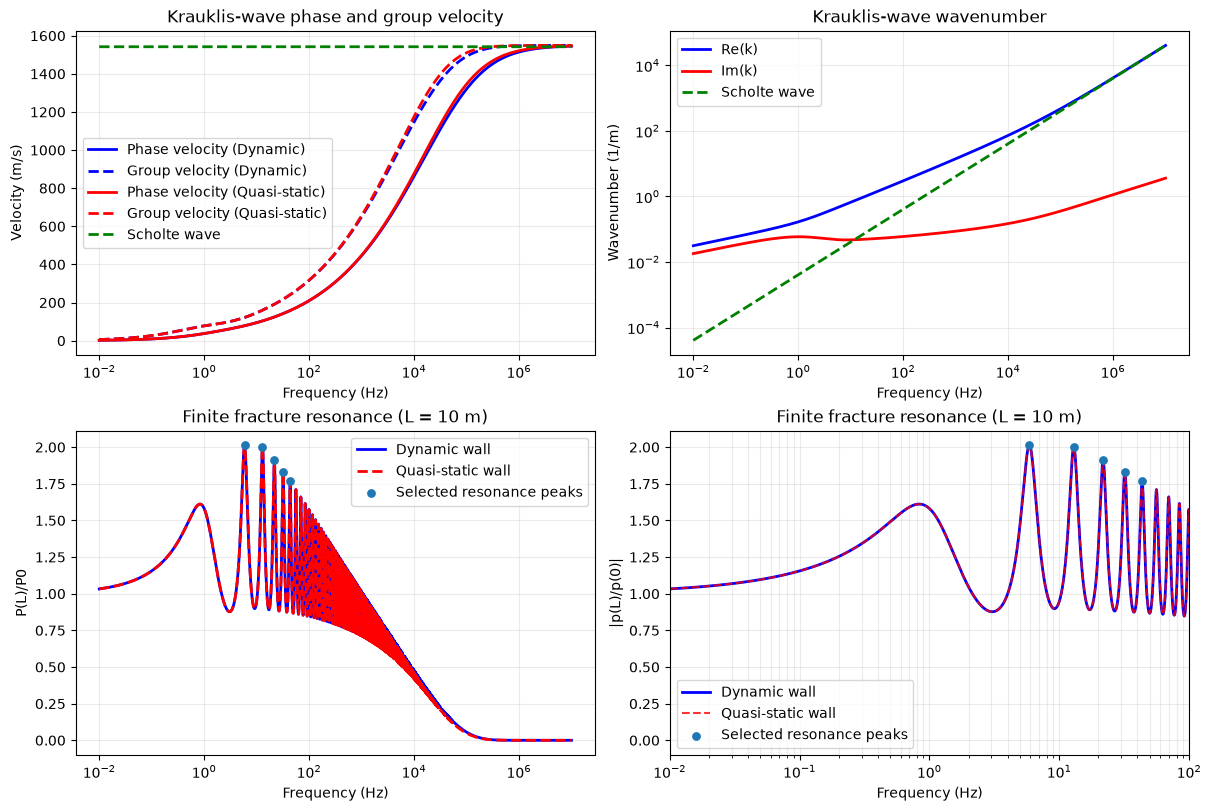

In [14]:
# ============================================================
# 5. Visualization
# ============================================================
fig, ax = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
# Phase and group velocity
ax[0,0].semilogx(
    frequencies,
    vp_dyn,
    label="Phase velocity (Dynamic)",
    linewidth=2,
    color='blue',
)
ax[0,0].semilogx(
    frequencies,
    vg_dyn,
    '--',
    label="Group velocity (Dynamic)",
    linewidth=2,
    color='blue',
)
ax[0,0].semilogx(
    frequencies,
    vp_sta,
    label="Phase velocity (Quasi-static)",
    linewidth=2,
    color='red',
)
ax[0,0].semilogx(
    frequencies,
    vg_sta,
    '--',
    label="Group velocity (Quasi-static)",
    linewidth=2,
    color='red',
)
ax[0,0].semilogx(
    frequencies,
    v_scholte,
    '--',
    label="Scholte wave",
    linewidth=2,
    color='green',
)
ax[0,0].set_xlabel("Frequency (Hz)")
ax[0,0].set_ylabel("Velocity (m/s)")
ax[0,0].set_title("Krauklis-wave phase and group velocity")
ax[0,0].grid(True, which="both", alpha=0.25)
ax[0,0].legend()
ax[1,1].set_xlim(1e-2,1e2)

# Wavenunmber
ax[0,1].loglog(
    frequencies,
    result_dynamic.k.real,
    label="Re(k)",
    linewidth=2,
    color='blue',
)
ax[0,1].loglog(
    frequencies,
    result_dynamic.k.imag,
    label="Im(k)",
    linewidth=2,
    color='red',
)
ax[0,1].loglog(
    frequencies,
    k_scholte,
    '--',
    label="Scholte wave",
    linewidth=2,
    color='green',
)
ax[0,1].set_xlabel("Frequency (Hz)")
ax[0,1].set_ylabel("Wavenumber (1/m)")
ax[0,1].set_title("Krauklis-wave wavenumber")
ax[0,1].grid(True, which="both", alpha=0.25)
ax[0,1].legend()
ax[1,1].set_xlim(1e-2,1e2)

# Finite-fracture resonance
H_w_dynamic = 1/np.cos(result_dynamic.k*L)
ax[1,0].semilogx(
    frequencies,
    result_dynamic.amplification,
    label="Dynamic wall",
    linewidth=2,
    color='blue',
)
ax[1,0].semilogx(
    frequencies,
    result_static.amplification,
    "--",
    label="Quasi-static wall",
    linewidth=2,
    color='red',
)
ax[1,0].scatter(
    frequencies[strongest],
    result_dynamic.amplification[strongest],
    s=28,
    zorder=3,
    label="Selected resonance peaks"
)
ax[1,0].set_xlabel("Frequency (Hz)")
ax[1,0].set_ylabel("P(L)/P0")
ax[1,0].set_title(f"Finite fracture resonance (L = {p.L:g} m)")
ax[1,0].grid(True, which="both", alpha=0.25)
ax[1,0].legend()
ax[1,1].set_xlim(1e-2,1e2)

# Finite-fracture resonance
ax[1,1].semilogx(
    frequencies,
    result_dynamic.amplification,
    label="Dynamic wall",
    color='blue',
    linewidth=2
)
ax[1,1].semilogx(
    frequencies,
    result_static.amplification,
    "--",
    color='red',
    label="Quasi-static wall",
    alpha=0.8
)
ax[1,1].scatter(
    frequencies[strongest],
    result_dynamic.amplification[strongest],
    s=28,
    zorder=3,
    label="Selected resonance peaks"
)
ax[1,1].set_xlabel("Frequency (Hz)")
ax[1,1].set_ylabel("|p(L)/p(0)|")
ax[1,1].set_title(f"Finite fracture resonance (L = {p.L:g} m)")
ax[1,1].grid(True, which="both", alpha=0.25)
ax[1,1].legend()
ax[1,1].set_xlim(1e-2,1e2)

plt.show()